**Cellule 1 : démarrage**

In [5]:
import os
REPO = "/content/anomaly-mvtec"
if not os.path.exists(REPO):
    !git clone https://github.com/maha-mrrk/anomaly-mvtec.git {REPO}
else:
    !git -C {REPO} pull
%cd {REPO}

remote: Enumerating objects: 6, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 4 (delta 2), reused 4 (delta 2), pack-reused 0 (from 0)
Unpacking objects: 100% (4/4), 458 bytes | 458.00 KiB/s, done.
From https://github.com/maha-mrrk/anomaly-mvtec
   7e2b178..82896b0  main       -> origin/main
Updating 7e2b178..82896b0
Fast-forward
 results/simsiam_frozen_results.csv | 4 ++++
 1 file changed, 4 insertions(+)
 create mode 100644 results/simsiam_frozen_results.csv
/content/anomaly-mvtec


**Cellule 2 : inventaire des fichiers**

In [6]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
R = f"{REPO}/results"; CATS = ["carpet", "screw", "cable"]
def rd(name):
    p = f"{R}/{name}"
    return pd.read_csv(p) if os.path.exists(p) else None

EXPECTED = ["baseline_results.csv", "vae_results.csv", "simsiam_results.csv", "simsiam_frozen_results.csv",
            "dino_results.csv", "t9_thresholds.csv", "t9_calibration.csv",
            "t11_attacks.csv", "t11_defenses.csv", "t12_edge.csv", "t12_edge_per_category.csv"]
for f in EXPECTED:
    print("OK     " if os.path.exists(f"{R}/{f}") else "MANQUE ", f)

OK      baseline_results.csv
OK      vae_results.csv
OK      simsiam_results.csv
OK      simsiam_frozen_results.csv
OK      dino_results.csv
OK      t9_thresholds.csv
OK      t9_calibration.csv
OK      t11_attacks.csv
OK      t11_defenses.csv
OK      t12_edge.csv
OK      t12_edge_per_category.csv


**Cellule 3 : tableau principal**

In [7]:
frames = []
b = rd("baseline_results.csv")
if b is not None: frames.append(b.assign(model="Baseline (image moyenne)", res=128))
v = rd("vae_results.csv")
if v is not None: frames.append(v[v.model == "VAE_beta0.01"].assign(model="VAE (β=0.01)", res=128))
s = rd("simsiam_results.csv")
if s is not None:
    s2 = s.rename(columns={"img_auc_mapmax": "img_auroc", "pix_auc": "pix_auroc"})
    s2["model"] = s2.model.map({"SimSiam-scratch": "SimSiam (scratch)", "SimSiam-ImageNet": "SimSiam (ImageNet)"})
    frames.append(s2[["model", "category", "img_auroc", "pix_auroc"]].assign(res=224))
fz = rd("simsiam_frozen_results.csv")
if fz is not None:
    fz2 = fz.rename(columns={"img_auc_mapmax": "img_auroc", "pix_auc": "pix_auroc"})
    frames.append(fz2[["category", "img_auroc", "pix_auroc"]].assign(model="ResNet-18 ImageNet (gelé)", res=224))
d = rd("dino_results.csv")
if d is not None: frames.append(d[d.model == "DINO-ViT-S/8_k1"].assign(model="DINO ViT-S/8 (k=1)", res=224))
main = pd.concat(frames, ignore_index=True)

ORDER = ["Baseline (image moyenne)", "VAE (β=0.01)", "SimSiam (scratch)", "SimSiam (ImageNet)",
         "ResNet-18 ImageNet (gelé)", "DINO ViT-S/8 (k=1)"]
def pivot(metric):
    p = main.pivot(index="model", columns="category", values=metric).reindex(columns=CATS)
    p["moyenne"] = p[CATS].mean(axis=1)
    return p.reindex([m for m in ORDER if m in p.index])

final = pd.concat({"AUROC image": pivot("img_auroc"), "AUROC pixel": pivot("pix_auroc"),
                   "AUPRO": pivot("aupro")}, axis=1)
final.round(3).to_csv(f"{R}/final_main_table.csv")
try: open(f"{R}/final_main_table.md", "w").write(final.round(3).to_markdown())
except Exception as ex: print("markdown non généré :", ex)
print(main.groupby("model").res.first().to_string())      # résolutions : à mentionner dans le rapport
final.round(3)

model
Baseline (image moyenne)     128
DINO ViT-S/8 (k=1)           224
ResNet-18 ImageNet (gelé)    224
SimSiam (ImageNet)           224
SimSiam (scratch)            224
VAE (β=0.01)                 128


AUROC image                       AUROC pixel  \
category                       carpet  screw  cable moyenne      carpet   
model                                                                     
Baseline (image moyenne)        0.395  0.230  0.635   0.420       0.715   
VAE (β=0.01)                    0.547  0.631  0.699   0.626       0.853   
SimSiam (scratch)               0.872  0.564  0.847   0.761       0.877   
SimSiam (ImageNet)              0.511  0.810  0.909   0.743       0.895   
ResNet-18 ImageNet (gelé)       0.920  0.898  0.930   0.916       0.983   
DINO ViT-S/8 (k=1)              0.997  0.943  0.983   0.974       0.995   

                                                 AUPRO                        
category                   screw  cable moyenne carpet  screw  cable moyenne  
model                                                                         
Baseline (image moyenne)   0.878  0.901   0.831  0.460  0.628  0.532   0.540  
VAE (β=0.01)               0.975  0.914   0.914  0.511  0.891  0.615   0.672  
SimSiam (scratch)          0.940  0.945   0.921    NaN    NaN    NaN     NaN  
SimSiam (ImageNet)         0.981  0.970   0.949    NaN    NaN    NaN     NaN  
ResNet-18 ImageNet (gelé)  0.982  0.967   0.977    NaN    NaN    NaN     NaN  
DINO ViT-S/8 (k=1)         0.992  0.982   0.990  0.981  0.964  0.942   0.962

**Cellule 4 : meilleur modèle par catégorie et figure**

,category,model,img_auroc
17,cable,DINO ViT-S/8 (k=1),0.983
15,carpet,DINO ViT-S/8 (k=1),0.997
16,screw,DINO ViT-S/8 (k=1),0.943


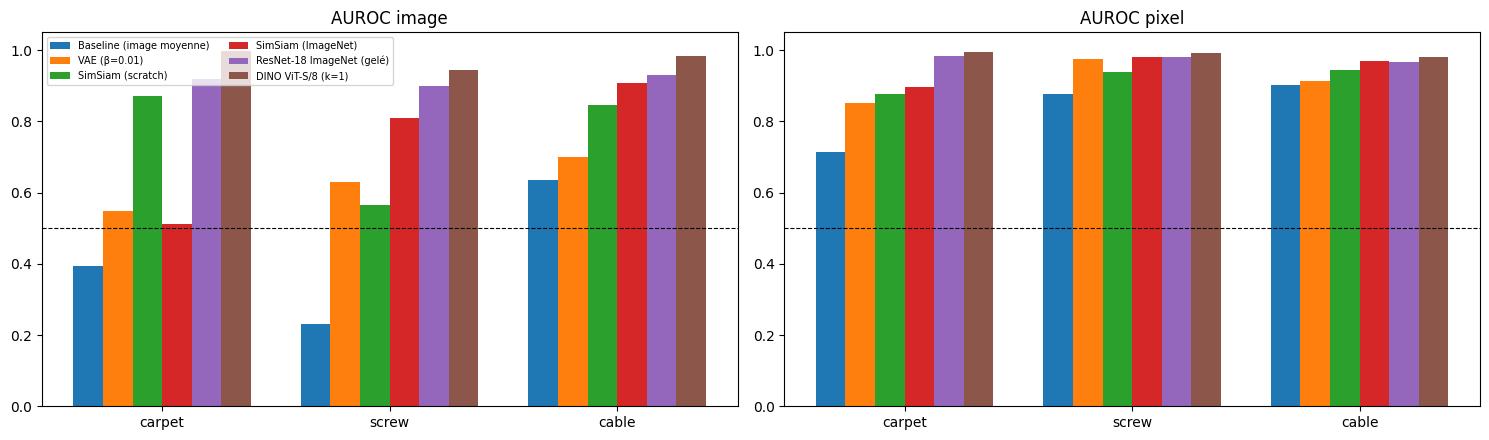

In [8]:
display(main.loc[main.groupby("category").img_auroc.idxmax(), ["category", "model", "img_auroc"]].round(3))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5)); w = 0.13
for a, metric, title in zip(ax, ["img_auroc", "pix_auroc"], ["AUROC image", "AUROC pixel"]):
    tab = pivot(metric)
    for j, m in enumerate(tab.index):
        a.bar(np.arange(len(CATS)) + j * w, tab.loc[m, CATS].values, w, label=m)
    a.set_xticks(np.arange(len(CATS)) + w * (len(tab) - 1) / 2); a.set_xticklabels(CATS)
    a.axhline(0.5, color="k", ls="--", lw=0.8); a.set_title(title); a.set_ylim(0, 1.05)
ax[0].legend(fontsize=7, ncol=2); plt.tight_layout()
plt.savefig(f"{R}/final_comparison.png", dpi=150); plt.show()

**Cellule 5 : ablations (VAE, DINO, SimSiam)**

In [9]:
if v is not None:
    ab_vae = pd.concat({m: v.pivot(index="model", columns="category", values=k)[CATS]
                        for m, k in [("AUROC image", "img_auroc"), ("AUROC pixel", "pix_auroc")]}, axis=1)
    ab_vae.round(3).to_csv(f"{R}/final_ablation_vae.csv"); display(ab_vae.round(3))
if d is not None:
    ab_dino = pd.concat({m: d.pivot(index="model", columns="category", values=k)[CATS]
                         for m, k in [("AUROC image", "img_auroc"), ("AUROC pixel", "pix_auroc")]}, axis=1)
    ab_dino.round(3).to_csv(f"{R}/final_ablation_dino.csv"); display(ab_dino.round(3))
if s is not None:
    ab_ss = s.set_index(["model", "category"])[["img_auc_knn1", "img_auc_knn3", "img_auc_knn5",
                                                "img_auc_mapmax", "pix_auc"]].unstack("category")
    ab_ss.round(3).to_csv(f"{R}/final_ablation_simsiam.csv"); display(ab_ss.round(3))

AUROC image               AUROC pixel              
category           carpet  screw  cable      carpet  screw  cable
model                                                            
VAE_beta0.001       0.603  0.579  0.706       0.848  0.975  0.911
VAE_beta0.01        0.547  0.631  0.699       0.853  0.975  0.914
VAE_beta0.1         0.584  0.609  0.701       0.858  0.972  0.922

AUROC image               AUROC pixel              
category             carpet  screw  cable      carpet  screw  cable
model                                                              
DINO-ViT-S/8_k1       0.997  0.943  0.983       0.995  0.992  0.982
DINO-ViT-S/8_k3       0.998  0.936  0.980       0.995  0.991  0.981
DINO-ViT-S/8_k5       0.998  0.931  0.978       0.995  0.990  0.981

img_auc_knn1               img_auc_knn3                \
category                cable carpet  screw        cable carpet  screw   
model                                                                    
SimSiam-ImageNet        0.906  0.293  0.598        0.894  0.291  0.541   
SimSiam-scratch         0.772  0.487  0.468        0.767  0.461  0.514   

                 img_auc_knn5               img_auc_mapmax                \
category                cable carpet  screw          cable carpet  screw   
model                                                                      
SimSiam-ImageNet        0.888  0.287  0.519          0.909  0.511  0.810   
SimSiam-scratch         0.759  0.427  0.512          0.847  0.872  0.564   

                 pix_auc                
category           cable carpet  screw  
model                                   
SimSiam-ImageNet   0.970  0.895  0.981  
SimSiam-scratch    0.945  0.877  0.940

**Cellule 6 : T9 (seuils et calibration)**

In [10]:
th, cal = rd("t9_thresholds.csv"), rd("t9_calibration.csv")
if th is not None:
    t9 = th[th.rule.isin(["P95(val_normal)", "P99(val_normal)", "Youden(calib)"])][
        ["model", "category", "rule", "TPR", "FPR", "F1"]]
    t9.to_csv(f"{R}/final_t9_thresholds.csv", index=False)
    display(t9.pivot_table(index=["model", "category"], columns="rule", values=["TPR", "FPR"]).round(3))
if cal is not None:
    display(cal.round(3))

FPR                                           TPR  \
rule           P95(val_normal) P99(val_normal) Youden(calib) P95(val_normal)   
model category                                                                 
DINO  cable              0.090           0.028         0.097           0.926   
      carpet             0.114           0.043         0.000           0.991   
      screw              0.077           0.000         0.096           0.814   
VAE   cable              0.034           0.021         0.366           0.248   
      carpet             0.457           0.157         0.314           0.471   
      screw              0.000           0.000         0.471           0.003   

                                              
rule           P99(val_normal) Youden(calib)  
model category                                
DINO  cable              0.913         0.896  
      carpet             0.991         0.973  
      screw              0.649         0.797  
VAE   cable              0.152         0.583  
      carpet             0.244         0.329  
      screw              0.000         0.652

,model,category,ECE_brut,ECE_Platt,Brier_brut,Brier_Platt
0,DINO,cable,0.192,0.044,0.125,0.059
1,DINO,carpet,0.180,0.037,0.066,0.018
2,DINO,screw,0.380,0.045,0.272,0.087
3,VAE,cable,0.292,0.055,0.295,0.215
4,VAE,carpet,0.531,0.030,0.482,0.181
5,VAE,screw,0.375,0.041,0.333,0.184


**Cellule 7 : T11 (attaques et défenses)**

AUROC image                                            \
                      propre FGSM 4/255 FGSM 8/255 PGD 2/255 PGD 4/255   
model                                                                    
DINO                   0.974      0.991      0.999     0.459     0.290   
DINO+flou              0.952        NaN        NaN     0.475     0.285   
SimSiam-ImageNet       0.743      0.808      0.921     0.144     0.242   
VAE                    0.626      0.448      0.524     0.499     0.404   
VAE-débruiteur         0.569        NaN        NaN     0.469     0.385   

                           défauts détectés (TPR)                        \
                 PGD 8/255                 propre FGSM 4/255 FGSM 8/255   
model                                                                     
DINO                 0.348                  0.913      0.978      0.996   
DINO+flou            0.239                  0.890        NaN        NaN   
SimSiam-ImageNet     0.475                  0.583      0.715      0.942   
VAE                  0.299                  0.225      0.110      0.108   
VAE-débruiteur       0.281                  0.278        NaN        NaN   

                                               défauts masqués             \
                 PGD 2/255 PGD 4/255 PGD 8/255          propre FGSM 4/255   
model                                                                       
DINO                 0.291     0.146     0.124             0.0      0.008   
DINO+flou            0.300     0.154     0.114             0.0        NaN   
SimSiam-ImageNet     0.037     0.032     0.193             0.0      0.159   
VAE                  0.132     0.089     0.026             0.0      0.364   
VAE-débruiteur       0.180     0.110     0.051             0.0        NaN   

                                                           
                 FGSM 8/255 PGD 2/255 PGD 4/255 PGD 8/255  
model                                                      
DINO                  0.000     0.694     0.848     0.867  
DINO+flou               NaN     0.675     0.835     0.881  
SimSiam-ImageNet      0.042     0.948     0.942     0.738  
VAE                   0.783     0.283     0.732     0.939  
VAE-débruiteur          NaN     0.396     0.640     0.868

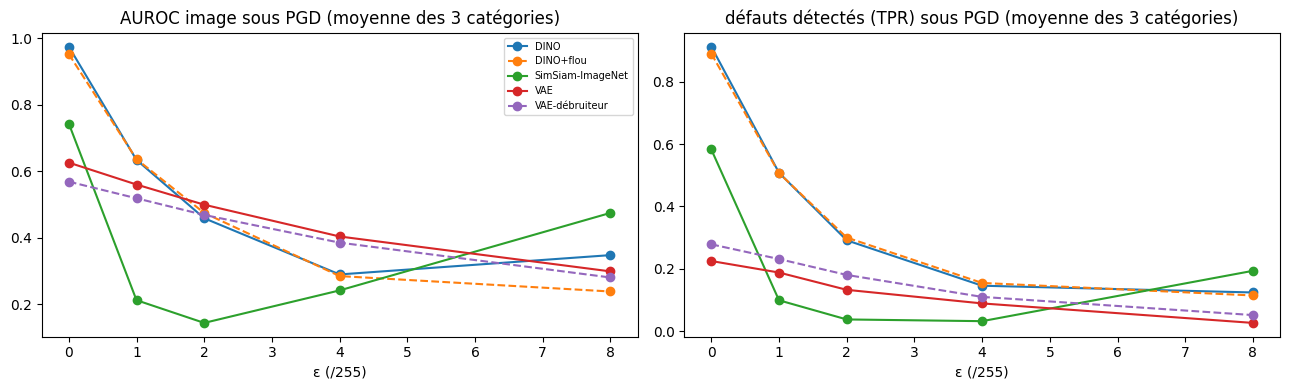

In [11]:
att, dfn = rd("t11_attacks.csv"), rd("t11_defenses.csv")
if att is not None:
    allatt = pd.concat([att, dfn]) if dfn is not None else att
    def summary(metric):
        cols = {}
        for atk, e in [("none", 0), ("FGSM", 4), ("FGSM", 8), ("PGD", 2), ("PGD", 4), ("PGD", 8)]:
            sub = allatt[(allatt.attack == atk) & (allatt.eps == e)]
            cols["propre" if atk == "none" else f"{atk} {e}/255"] = sub.groupby("model")[metric].mean()
        return pd.DataFrame(cols)
    t11 = pd.concat({"AUROC image": summary("img_auroc"), "défauts détectés (TPR)": summary("TPR"),
                     "défauts masqués": summary("masked")}, axis=1)
    t11.round(3).to_csv(f"{R}/final_t11_summary.csv"); display(t11.round(3))

    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for m, g in allatt[allatt.attack.isin(["none", "PGD"])].groupby("model"):
        style = "o--" if ("débruiteur" in m or "flou" in m) else "o-"       # tirets = modèles défendus
        for a, metric, title in zip(ax, ["img_auroc", "TPR"], ["AUROC image", "défauts détectés (TPR)"]):
            c = g.groupby("eps")[metric].mean()
            a.plot(c.index, c.values, style, label=m); a.set_title(f"{title} sous PGD (moyenne des 3 catégories)")
            a.set_xlabel("ε (/255)")
    ax[0].legend(fontsize=7); plt.tight_layout()
    plt.savefig(f"{R}/final_t11_curves.png", dpi=150); plt.show()

**Cellule 8 : T12 (compression)**

In [12]:
e = rd("t12_edge.csv")
if e is not None:
    e = e.set_index("variant")
    ref = e.loc["FP32 (réf.)"]
    e["taille_x"] = e.total_mb / ref.total_mb
    e["latence_x"] = e.lat_total_ms / ref.lat_total_ms
    e["delta_auroc"] = e.img_auroc - ref.img_auroc
    e.round(3).to_csv(f"{R}/final_t12_summary.csv"); display(e.round(3))

,img_auroc,pix_auroc,total_mb,model_mb,bank_mb,lat_vit_ms,lat_knn_ms,lat_total_ms,taille_x,latence_x,delta_auroc
variant,,,,,,,,,,,
FP32 (réf.),0.974,0.990,351.664,86.735,264.929,669.557,2538.269,3207.826,1.000,1.000,0.000
INT8 dynamique,0.972,0.990,287.995,23.066,264.929,582.474,2502.466,3084.940,0.819,0.962,-0.002
Banque 25 %,0.960,0.988,152.967,86.735,66.232,621.796,583.888,1205.684,0.435,0.376,-0.014
Banque 10 %,0.949,0.987,113.227,86.735,26.492,626.153,225.224,851.377,0.322,0.265,-0.025
ViT-S/16,0.945,0.984,152.949,86.716,66.232,111.946,187.709,299.655,0.435,0.093,-0.029
ViT-S/16 + INT8 + banque 25 %,0.892,0.979,39.606,23.048,16.558,96.795,31.898,128.694,0.113,0.040,-0.082
Pruning 30 %,0.977,0.990,351.664,86.735,264.929,626.740,2394.391,3021.131,1.000,0.942,0.003
Pruning 50 %,0.978,0.988,351.664,86.735,264.929,589.427,2407.132,2996.559,1.000,0.934,0.004


In [13]:
%cd /content/anomaly-mvtec
!ls results | grep final_
!zip -o /content/results08.zip results/final_*
from google.colab import files
files.download("/content/results08.zip")

/content/anomaly-mvtec
final_ablation_dino.csv
final_ablation_simsiam.csv
final_ablation_vae.csv
final_comparison.png
final_main_table.csv
final_main_table.md
final_t11_curves.png
final_t11_summary.csv
final_t12_summary.csv
final_t9_thresholds.csv
  adding: results/final_ablation_dino.csv (deflated 56%)
  adding: results/final_ablation_simsiam.csv (deflated 64%)
  adding: results/final_ablation_vae.csv (deflated 48%)
  adding: results/final_comparison.png (deflated 25%)
  adding: results/final_main_table.csv (deflated 55%)
  adding: results/final_main_table.md (deflated 83%)
  adding: results/final_t11_curves.png (deflated 6%)
  adding: results/final_t11_summary.csv (deflated 67%)
  adding: results/final_t12_summary.csv (deflated 46%)
  adding: results/final_t9_thresholds.csv (deflated 65%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>